# Data Science Assignment: Session 5
## Topic: Sampling in Data Science

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 5 - Sampling  

---

### Core Concept: Population vs. Sample

- **Population ($N$):** The entire, complete group of individuals, events, or objects that you want to draw conclusions about.
- **Sample ($n$):** A specific, manageable subset drawn from the population, used to infer characteristics (parameters) of the whole population.

```
     ┌─────────────────────────────────────────────────────┐
     │                  POPULATION (N)                     │
     │  (Entire universe of data: All users, all orders)    │
     │         [x]    [x]     [x]     [x]    [x]           │
     │     [x]     ┌───────────────────┐    [x]            │
     │             │     SAMPLE (n)    │                   │
     │        [x]  │  [x]   [x]   [x]  │         [x]       │
     │             └───────────────────┘                   │
     │         [x]            [x]            [x]           │
     └─────────────────────────────────────────────────────┘
                    ▲                 │
                    │ (Inference)     │ (Sampling Technique)
                    └─────────────────┘
```

---

## Task 1: Population vs. Sample in Everyday Apps
> **Problem Statement:** List 3 examples of 'population' and 'sample' in the context of apps you use daily (like Instagram followers, Zomato restaurants, or Flipkart products). For each, clearly define what would be considered the population and what would be a sample.

In [1]:
import pandas as pd

# 3 Real-World App Examples of Population vs Sample
app_examples = [
    {
        "App": "Instagram",
        "Domain / Context": "Followers & User Engagement",
        "Population (N)": "All 2.5 Billion active users (or all 50,000 followers of a creator)",
        "Sample (n)": "500 randomly selected followers chosen for a story poll / survey",
        "Sampling Purpose": "Gauge audience sentiment without polling millions"
    },
    {
        "App": "Zomato",
        "Domain / Context": "Restaurant Hygiene & Quality",
        "Population (N)": "All 300,000+ registered restaurants listed across India",
        "Sample (n)": "200 restaurants randomly audited across 10 major cities",
        "Sampling Purpose": "Physical inspection of 300k kitchens is logistically impossible"
    },
    {
        "App": "Flipkart",
        "Domain / Context": "Catalog Discounts & Pricing",
        "Population (N)": "All 150 Million listed product SKUs in Flipkart's catalog",
        "Sample (n)": "1,000 smartphone listings randomly drawn from Electronics",
        "Sampling Purpose": "Fast analytical insight into seasonal price discounts"
    }
]

df_examples = pd.DataFrame(app_examples)
display(df_examples)

App,Domain / Context,Population (N),Sample (n),Sampling Purpose
Instagram,Followers & User Engagement,"All 2.5 Billion registered active Instagram users worldwide (or all 50,000 followers of a specific creator).",A randomly selected group of 500 followers chosen to participate in a feedback survey or poll.,"To understand audience sentiment without needing responses from all 50,000 followers."
Zomato,Restaurant Ratings & Food Hygiene,"Every registered dining & delivery restaurant listed on Zomato across India (~300,000 outlets).",200 restaurants randomly selected across 10 major metropolitan cities for quarterly food safety audits.,"Conducting on-site physical audits across 300,000 restaurants is physically impossible and cost-prohibitive."
Flipkart,Product Pricing & Delivery Fees,All 150 Million active product SKUs listed across all catalog categories on Flipkart.,"1,000 smartphone product listings randomly sampled from the 'Electronics' division during Big Billion Days.",To evaluate discount percentage trends and shipping fee benchmarks with instant computational execution.


## Task 2: Simulating Simple Random Sampling in Python
> **Problem Statement:** Write a Python script that simulates random sampling: given a list of 1000 fake user IDs (e.g., `user1` to `user1000`), select 50 random users to simulate a survey sample. Print the selected user IDs.  
> *Hint:* Use the `random.sample()` function from Python's `random` module.

### Properties of `random.sample()`:
1. **Sampling Without Replacement:** Every selected user ID is unique (no duplicate entries in the survey).
2. **Equal Probability:** Each user ID has an identical probability ($P = \frac{1}{N} = \frac{1}{1000} = 0.1\%$) of being selected.

In [2]:
import random

# Step 1: Generate 1,000 fake user IDs (user1 to user1000)
population_users = [f"user{i}" for i in range(1, 1001)]

# Step 2: Use random.sample() to select 50 random users without replacement
random.seed(42) # Set seed for reproducibility
sample_size = 50
survey_sample = random.sample(population_users, sample_size)

print(f"Population Size (N)     : {len(population_users)} users (user1 to user1000)")
print(f"Sample Size (n)         : {len(survey_sample)} users")
print(f"Sampling Ratio (n / N)  : {len(survey_sample)/len(population_users):.1%}")
print(f"Duplicate Check         : {len(survey_sample) == len(set(survey_sample))} (Zero duplicates, sampling without replacement)")
print("-" * 80)
print("SELECTED 50 RANDOM SURVEY USER IDs:")
print("-" * 80)

# Print in neat rows of 10
for i in range(0, len(survey_sample), 10):
    print(", ".join(survey_sample[i:i+10]))

Population Size (N)     : 1000 users (user1 to user1000)
Sample Size (n)         : 50 users
Sampling Ratio (n / N)  : 5.0%
Duplicate Check         : True (Zero duplicates, sampling without replacement)
--------------------------------------------------------------------------------
SELECTED 50 RANDOM SURVEY USER IDs:
--------------------------------------------------------------------------------
user655, user115, user26, user760, user282, user251, user229, user143, user755, user105
user693, user759, user914, user559, user90, user605, user433, user33, user31, user96
user224, user239, user518, user617, user28, user575, user204, user734, user666, user719
user430, user226, user460, user604, user285, user829, user891, user7, user778, user826
user164, user715, user349, user160, user221, user981, user782, user345, user95, user390


## Task 3: Why Use Sampling on Swiggy Food Delivery Times?
> **Problem Statement:** Imagine you are analyzing food delivery times on Swiggy. Explain in 2-3 sentences why you would use sampling instead of collecting data from every single order ever made.

### Explanation (2–3 Sentences):

1. **Computational & Infrastructure Efficiency:** Querying hundreds of millions of historical order logs from Swiggy's databases would consume enormous cloud compute resources, cost thousands of dollars, and take hours to query, whereas a representative sample yields actionable insights in seconds.
2. **Operational Relevance (Diminishing Returns):** Delivery speeds from 5 years ago under obsolete traffic systems or closed restaurants are irrelevant to current operations; analyzing a statistically sufficient recent sample (e.g., 5,000 orders) provides high statistical confidence with negligible margin of error.
3. **Speed of Decision-Making:** Real-time logistics optimization (such as rider dispatch algorithms) requires immediate analytical turnaround that is only feasible when operating on live samples.

## Task 4: Identifying Bias in Spotify Music Preferences Survey
> **Problem Statement:** Given this scenario: A survey about music preferences is only sent to users who recently streamed Bollywood songs on Spotify. Identify and explain the type of bias this introduces in the sample.

### 1. Identified Type of Bias:
**Sampling Bias** (specifically **Undercoverage Bias** and **Selection Bias**).

### 2. Explanation of the Bias:
- **Systematic Exclusion:** By restricting the survey exclusively to users who streamed Bollywood songs, Spotify's sampling frame completely excludes users who exclusively listen to International Pop, Hip-Hop, Punjabi, K-Pop, EDM, Classical, or Indie music.
- **Distorted Representation:** Every respondent in this sample has an inherent pre-existing preference for Bollywood music. As a result, the survey will falsely conclude that Bollywood is universally preferred by all Spotify subscribers, severely over-representing one sub-culture while silencing non-Bollywood listeners.
- **Invalid Generalization:** The resulting sample cannot be generalized to the entire Spotify user population without severe statistical skew.

## Task 5: Sampling Techniques for BookMyShow Movie Booking Habits
> **Problem Statement:** Choose any two types of sampling (for example: random sampling, stratified sampling, systematic sampling, cluster sampling). For each, describe how you would use it to select a sample of users from BookMyShow to study movie booking habits.

We choose: **1. Stratified Random Sampling** and **2. Systematic Sampling**.

### Technique 1: Stratified Random Sampling
- **How to Apply to BookMyShow:**
  1. Divide BookMyShow's user base into non-overlapping subgroups (**strata**) based on geographic tier:
     - *Stratum 1:* Tier 1 Metros (Mumbai, Delhi-NCR, Bengaluru)
     - *Stratum 2:* Tier 2 Cities (Pune, Ahmedabad, Jaipur, Chandigarh)
     - *Stratum 3:* Tier 3 & Non-Metro Cities
  2. Draw a proportional random sample from each stratum (e.g., 50% from Metros, 30% from Tier 2, 20% from Tier 3).
- **Why it is Ideal:**
  Booking habits vary drastically across city tiers. Metro users frequently book premium formats (IMAX, 4DX, Recliner lounges) at high price points (₹400–₹1,000), while Tier 3 users frequent single-screen theaters at lower price points. Stratification guarantees that smaller regional demographics are not overshadowed by metro transaction volumes.

---

### Technique 2: Systematic Sampling
- **How to Apply to BookMyShow:**
  1. Sort all incoming movie ticket bookings sequentially by checkout timestamp during a blockbuster opening weekend.
  2. Define a sampling interval $k$ based on total expected bookings $N$ and target sample size $n$ (e.g., $k = \frac{100,000}{1,000} = 100$).
  3. Pick a random starting customer between $1$ and $100$ (e.g., Customer #23).
  4. Automatically prompt **every 100th customer** thereafter (Customer #23, #123, #223, #323...) with a post-booking questionnaire.
- **Why it is Ideal:**
  Systematic sampling is trivial to automate in a high-throughput transaction stream. It guarantees even time dispersion across morning shows, matinees, prime evening shows, and midnight screenings without clustering at a single time of day.

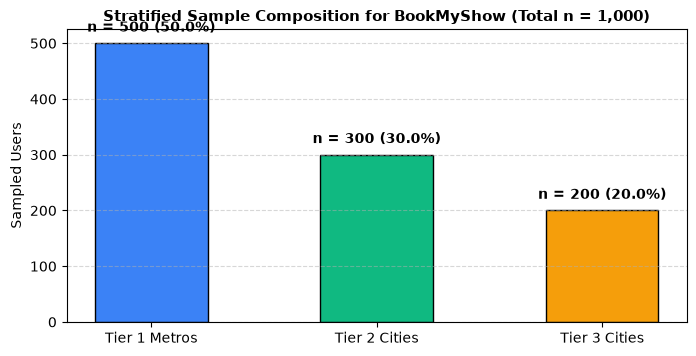

In [3]:
import matplotlib.pyplot as plt

# Visualizing BookMyShow Stratified Sample Breakdown
strata = {"Tier 1 Metros": 500, "Tier 2 Cities": 300, "Tier 3 Cities": 200}

plt.figure(figsize=(8, 3.8))
bars = plt.bar(strata.keys(), strata.values(), color=['#3b82f6', '#10b981', '#f59e0b'], width=0.5, edgecolor='black')
plt.title("Stratified Sample Composition for BookMyShow (Total n = 1,000)", fontsize=11, fontweight="bold")
plt.ylabel("Sampled Users", fontsize=10)
plt.ylim(0, 600)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 15, f"n = {int(h)} ({int(h)/10:.0f}%)", ha='center', va='bottom', fontweight='bold')

plt.show()